# Étape 5 : DrBERT avec découpage en chunks et fenêtres de contexte

Première approche Deep Learning. On utilise DrBERT (`Dr-BERT/DrBERT-7GB`), un modèle pré-entraîné sur des textes médicaux en français. Il est limité à 512 tokens, alors qu'une bonne partie des comptes rendus est plus longue. Les textes sont donc préparés de la façon suivante :

| Document | Traitement |
|---|---|
| ≤ 510 tokens | gardé en entier |
| > 510 tokens avec une mention tabac (regex) | fenêtres de 50 tokens de chaque côté des mentions, mises bout à bout |
| > 510 tokens sans mention | découpé en morceaux de 510 tokens |

Un document peut donc donner plusieurs séquences, on regroupe ensuite leurs prédictions pour avoir une seule prédiction par document. Le split train/test est le même que dans `04_ML.ipynb` pour pouvoir comparer les résultats.

Notebook exécuté sur Google Colab (GPU T4).

## Installation et configuration

In [1]:
%pip install -q "transformers>=4.48" "accelerate>=0.34" sentencepiece protobuf pyarrow

In [2]:
import gc, json, os, re, string, sys, time, warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

import transformers
from transformers import (AutoConfig, AutoModelForSequenceClassification, AutoTokenizer,
                          DataCollatorWithPadding, Trainer, TrainingArguments, set_seed)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, classification_report, cohen_kappa_score,
                             confusion_matrix, f1_score, precision_recall_fscore_support)

warnings.filterwarnings("ignore", category=FutureWarning)
transformers.logging.set_verbosity_error()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| transformers", transformers.__version__, "| device :", DEVICE)
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(0))

# le T4 ne supporte pas le bf16, on passe en fp16
USE_BF16 = DEVICE == "cuda" and torch.cuda.is_bf16_supported() and torch.cuda.get_device_properties(0).major >= 8
USE_FP16 = DEVICE == "cuda" and not USE_BF16
AMP_DTYPE = torch.bfloat16 if USE_BF16 else torch.float16

torch 2.14.1+cu130 | transformers 5.22.1 | device : cuda
Tesla T4


In [3]:
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/stage_m2"
else:
    BASE_DIR = "."

DATA_DIR = os.path.join(BASE_DIR, "data")
CSV_PATH = os.path.join(DATA_DIR, "annotated_corrected.csv")
PARQUET_PATH = os.path.join(DATA_DIR, "train-00000-of-00001.parquet")
RUN_NAME = "drbert_chunking"
OUT_DIR = os.path.join(BASE_DIR, "results", RUN_NAME)
CKPT_DIR = f"/content/ckpt_{RUN_NAME}" if IN_COLAB else os.path.join("ckpt", RUN_NAME)
os.makedirs(OUT_DIR, exist_ok=True)

# "parquet" : texte brut avec ponctuation, "csv" : texte nettoyé comme pour le ML
TEXT_SOURCE = "parquet"

SEED, TEST_SIZE = 42, 0.2   # même split que 04_ML
VAL_SIZE = 0.15

USE_CLASS_WEIGHTS = True
MODEL_CHECKPOINT = "Dr-BERT/DrBERT-7GB"
MAX_LEN = 512
CTX_TOKENS = 50

EPOCHS, LR, WEIGHT_DECAY, WARMUP_RATIO = 8, 2e-5, 0.01, 0.1
TRAIN_BS, GRAD_ACC, EVAL_BS = 8, 2, 32

# même regex que dans preproc.py
RE_TABAC = re.compile(
    r"\btabac\b|\btabagisme|\btabagique|intoxication tabagique|"
    r"(alcoolo|éthylo|ethylo)[- ]?tabagi|post[- ]?tabagi|"
    r"\bfumeu(r|se)s?\b|\bnon[- ]?fumeu(r|se)|\b(ancien(ne)?|ex)[- ]?fumeu(r|se)|"
    r"jamais\s+fum|\bfum(e|ait|aient|er|é)\b|\bcigarettes?\b|\bcig\b|\bcigares?\b|"
    r"cigarettes? électronique|\bvapot|e-cigarette|\bla pipe\b|nicotin|"
    r"\d\s*PA\b|\bpaquets?\b|paquets?[- ]?ann[ée]es?|\bsevr|sevrage tabagique|tabacolog",
    flags=re.IGNORECASE,
)

set_seed(SEED)
assert os.path.exists(CSV_PATH), CSV_PATH

Mounted at /content/drive


## 5.1 Données et split train / test

On reprend exactement le split de `04_ML.ipynb` (même `LabelEncoder`, `test_size=0.2`, `random_state=42`, stratifié), ce qui donne 477 documents en train et 120 en test. Le split est fait sur les documents, avant tout découpage, donc un même document ne peut pas se retrouver dans le train et dans le test.

Le texte de `annotated_corrected.csv` n'a plus de ponctuation, ce qui est gênant pour un transformer (négations, abréviations...). On récupère donc le texte brut dans le parquet PARHAF à partir des `id`, en vérifiant qu'il correspond bien au texte du CSV une fois nettoyé.

15 % du train est mis de côté comme validation pour choisir la meilleure époque.

In [4]:
df = pd.read_csv(CSV_PATH)[["id", "text", "label"]].copy()
df["label"] = df["label"].astype(str).str.strip()

le = LabelEncoder()
y_all = le.fit_transform(df["label"])
CLASSES = list(le.classes_)
NUM_LABELS = len(CLASSES)
ID2LABEL = {i: c for i, c in enumerate(CLASSES)}
LABEL2ID = {c: i for i, c in enumerate(CLASSES)}
df["label_id"] = y_all

idx_train, idx_test = train_test_split(df.index.values, test_size=TEST_SIZE, random_state=SEED, stratify=y_all)


def clean_like_preproc(s):
    # même nettoyage que clean_text dans preproc.py
    s = re.sub(rf"[{string.punctuation}]", " ", str(s))
    return re.sub(r"\s+", " ", s).strip()


def load_raw_texts(parquet_path):
    pq = pd.read_parquet(parquet_path, columns=["id", "documents"])
    out = {}
    for rid, docs in zip(pq["id"], pq["documents"]):
        texts = list(docs["text"])
        if len(list(docs["type"])) > 1:
            for k, t in enumerate(texts, start=1):
                out[f"{rid}_{k}"] = t
        else:
            out[str(rid)] = texts[0]
    return out


if TEXT_SOURCE == "parquet":
    from difflib import SequenceMatcher
    raw = load_raw_texts(PARQUET_PATH)
    found = df["id"].map(raw)
    # quelques textes du csv ont perdu des caractères spéciaux à l'export, d'où la tolérance
    same = np.array([isinstance(r, str) and (clean_like_preproc(r) == c
                                             or SequenceMatcher(None, clean_like_preproc(r), c).ratio() >= 0.99)
                     for r, c in zip(found, df["text"])])
    print(f"{same.sum()}/{len(df)} textes remplacés par le texte brut")
    df["text"] = np.where(same, found, df["text"])
    del raw

df_train_full = df.loc[idx_train].copy()
df_test = df.loc[idx_test].copy()

df_train, df_val = train_test_split(df_train_full, test_size=VAL_SIZE, random_state=SEED,
                                    stratify=df_train_full["label_id"])

print(f"Train : {len(df_train)} | Validation : {len(df_val)} | Test : {len(df_test)}")
display(pd.DataFrame({s: d["label"].value_counts() for s, d in
                      [("train", df_train), ("val", df_val), ("test", df_test)]}).loc[CLASSES])

597/597 textes remplacés par le texte brut
Train : 405 | Validation : 72 | Test : 120


,train,val,test
label,,,
Ancien fumeur,52,10,16
Fumeur actuel,63,11,18
Non mentionné,204,36,61
Non-fumeur,86,15,25


## 5.2 Fonctions utilitaires

Ces fonctions sont reprises telles quelles dans les notebooks 06 et 07 :
- un `Trainer` avec une cross-entropy pondérée par classe, à cause du déséquilibre des labels ;
- le regroupement des prédictions par document ;
- l'évaluation sur le test, qui sauvegarde les prédictions et un `metrics.json` pour pouvoir comparer les approches dans le notebook 08.

In [5]:
class SeqDataset(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        r = self.records[i]
        return {"input_ids": r["input_ids"], "attention_mask": [1] * len(r["input_ids"]), "labels": int(r["label_id"])}


class WeightedTrainer(Trainer):
    # Trainer avec une cross-entropy pondérée par classe
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights
        self.model_accepts_loss_kwargs = False

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits.float()
        weight = self.class_weights.to(logits.device) if self.class_weights is not None else None
        loss = F.cross_entropy(logits, labels, weight=weight)
        return (loss, outputs) if return_outputs else loss


def get_class_weights(label_ids):
    if not USE_CLASS_WEIGHTS:
        return None
    present = np.unique(label_ids)
    w = np.ones(NUM_LABELS, dtype=np.float32)
    w[present] = compute_class_weight("balanced", classes=present, y=np.asarray(label_ids))
    print("Poids des classes :", {c: round(float(x), 3) for c, x in zip(CLASSES, w)})
    return torch.tensor(w, dtype=torch.float32)


def softmax_np(logits):
    logits = np.asarray(logits, dtype=np.float64)
    e = np.exp(logits - logits.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def aggregate_probs(seq_doc_ids, probs, method="mean", tau=0.5):
    # mean : moyenne des séquences du document
    # max_evidence : si une séquence donne une classe tabac avec p >= tau, on garde cette séquence
    p = pd.DataFrame(np.asarray(probs), columns=CLASSES)
    p["doc_id"] = list(seq_doc_ids)
    mean = p.groupby("doc_id", sort=False)[CLASSES].mean()
    if method == "mean":
        return mean
    tabac_cols = [c for c in CLASSES if c != "Non mentionné"]
    out = mean.copy()
    for d, g in p.groupby("doc_id", sort=False):
        best = g[tabac_cols].max(axis=1)
        if best.max() >= tau:
            out.loc[d] = g.loc[best.idxmax(), CLASSES].values
    return out


def make_compute_metrics(seq_doc_ids, doc_true, method="mean", extra_true=(), extra_pred=()):
    # métriques par document ; extra_true / extra_pred = documents classés sans le modèle (regex de la cascade)
    def fn(eval_pred):
        logits = eval_pred.predictions[0] if isinstance(eval_pred.predictions, tuple) else eval_pred.predictions
        agg = aggregate_probs(seq_doc_ids, softmax_np(logits), method=method)
        yt = [doc_true[d] for d in agg.index] + list(extra_true)
        yp = list(agg.values.argmax(1)) + list(extra_pred)
        return {"f1_macro": f1_score(yt, yp, average="macro", zero_division=0),
                "accuracy": accuracy_score(yt, yp),
                "kappa": cohen_kappa_score(yt, yp)}
    return fn


@torch.no_grad()
def predict_probs(model, tokenizer, records, batch_size=16, pad_to=None):
    model.eval()
    # tri par longueur pour limiter le padding
    order = np.argsort([len(r["input_ids"]) for r in records])[::-1]
    collator = DataCollatorWithPadding(tokenizer, padding="max_length" if pad_to else "longest", max_length=pad_to)
    ds = SeqDataset([records[i] for i in order])
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, collate_fn=collator)
    out = []
    for batch in loader:
        batch.pop("labels", None)
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with torch.autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=DEVICE == "cuda"):
            logits = model(**batch).logits
        out.append(torch.softmax(logits.float(), dim=-1).cpu().numpy())
    probs_sorted = np.concatenate(out)
    probs = np.empty_like(probs_sorted)
    probs[order] = probs_sorted
    return probs


def kappa_level(k):
    # même échelle que dans rules.py
    if k < 0: return "Désaccord"
    if k <= 0.2: return "Très faible"
    if k <= 0.4: return "Faible"
    if k <= 0.6: return "Modéré"
    if k <= 0.8: return "Fort"
    return "Presque parfait"


def evaluate_and_save(name, doc_ids, y_true, y_pred, probs, timings, extra_cols=None, extra_metrics=None, config=None):
    y_true, y_pred, probs = np.asarray(y_true), np.asarray(y_pred), np.asarray(probs)
    labels = np.arange(NUM_LABELS)
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average="macro", zero_division=0)
    kappa = cohen_kappa_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    print(f"{name} - test ({len(y_true)} documents)")
    print(f"F1 macro : {f1:.4f} | Accuracy : {acc:.4f} | Précision : {prec:.4f} | Rappel : {rec:.4f}")
    print(f"Kappa : {kappa:.4f} ({kappa_level(kappa)})\n")
    print(classification_report(y_true, y_pred, labels=labels, target_names=CLASSES, digits=3, zero_division=0))

    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(f"Matrice de confusion - {name}")
    ax.set_ylabel("Vérité terrain")
    ax.set_xlabel("Prédiction")
    plt.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, "confusion_matrix.png"), dpi=150)
    plt.show()

    pred_df = pd.DataFrame({"doc_id": list(doc_ids),
                            "y_true": [ID2LABEL[i] for i in y_true], "y_pred": [ID2LABEL[i] for i in y_pred],
                            "y_true_id": y_true, "y_pred_id": y_pred})
    for j, c in enumerate(CLASSES):
        pred_df[f"proba_{c}"] = probs[:, j]
    for k, v in (extra_cols or {}).items():
        pred_df[k] = list(v)
    pred_df.to_csv(os.path.join(OUT_DIR, "predictions_test.csv"), index=False)

    report = classification_report(y_true, y_pred, labels=labels, target_names=CLASSES, output_dict=True, zero_division=0)
    metrics = {
        "Modèle": name, "run_name": RUN_NAME, "timestamp": datetime.now().isoformat(timespec="seconds"),
        "n_test_docs": int(len(y_true)), "classes": CLASSES,
        "Accuracy": round(float(acc), 4), "Precision (macro)": round(float(prec), 4),
        "Recall (macro)": round(float(rec), 4), "F1-score (macro)": round(float(f1), 4),
        "kappa": round(float(kappa), 4), "kappa_level": kappa_level(kappa),
        "per_class": {c: {k: round(float(v), 4) for k, v in report[c].items()} for c in CLASSES},
        "confusion_matrix": cm.tolist(), **timings, **(extra_metrics or {}),
        "split": {"test_size": TEST_SIZE, "random_state": SEED, "val_size": VAL_SIZE, "text_source": TEXT_SOURCE},
        "config": config or {},
    }
    with open(os.path.join(OUT_DIR, "metrics.json"), "w", encoding="utf-8") as f:
        json.dump(metrics, f, ensure_ascii=False, indent=2, default=str)
    return metrics, pred_df


def make_training_args(group_by_length=False, **kwargs):
    # group_by_length a changé de nom dans transformers 5
    import inspect
    valid = inspect.signature(TrainingArguments.__init__).parameters
    if group_by_length:
        if "train_sampling_strategy" in valid:
            kwargs["train_sampling_strategy"] = "group_by_length"
        else:
            kwargs["group_by_length"] = True
    return TrainingArguments(**{k: v for k, v in kwargs.items() if k in valid})


def vram_peak_gb():
    return round(torch.cuda.max_memory_allocated() / 1024**3, 2) if DEVICE == "cuda" else None


def free_memory():
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

## 5.3 Construction des séquences

Chaque document est tokenisé en entier. Grâce aux offsets du tokenizer, on retrouve la position en tokens des mentions trouvées par la regex. Quand deux fenêtres se chevauchent, elles sont fusionnées. Si les fenêtres d'un document ne tiennent pas dans 512 tokens, on crée une séquence de plus pour ne perdre aucune mention.

In [6]:
def load_tokenizer(ckpt):
    # avec transformers 5, AutoTokenizer n'arrive pas toujours à charger le tokenizer de DrBERT
    try:
        return AutoTokenizer.from_pretrained(ckpt, use_fast=True)
    except Exception:
        from transformers import PreTrainedTokenizerFast
        return PreTrainedTokenizerFast.from_pretrained(ckpt)


tokenizer = load_tokenizer(MODEL_CHECKPOINT)
assert tokenizer.is_fast   # nécessaire pour les offsets
BODY_LEN = MAX_LEN - tokenizer.num_special_tokens_to_add(pair=False)   # 510
print(type(tokenizer).__name__, "| BODY_LEN =", BODY_LEN)

config.json:   0%|          | 0.00/641 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/653 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B /  791kB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/353 [00:00<?, ?B/s]

TokenizersBackend | BODY_LEN = 510


In [7]:
def encode_doc(text):
    enc = tokenizer(text, add_special_tokens=False, return_offsets_mapping=True, truncation=False, verbose=False)
    return enc["input_ids"], enc["offset_mapping"]


def char_to_token_spans(char_spans, offsets):
    # positions en caractères -> positions en tokens
    starts = np.array([o[0] for o in offsets])
    ends = np.array([o[1] for o in offsets])
    spans = []
    for cs, ce in char_spans:
        idx = np.where((starts < ce) & (ends > cs))[0]
        if len(idx):
            spans.append((int(idx[0]), int(idx[-1])))
    return spans


def merge_windows(tok_spans, n_tokens, ctx):
    wins = sorted((max(0, a - ctx), min(n_tokens, b + 1 + ctx)) for a, b in tok_spans)
    merged = []
    for s, e in wins:
        if merged and s <= merged[-1][1]:
            merged[-1][1] = max(merged[-1][1], e)
        else:
            merged.append([s, e])
    return merged


def pack_segments(segments, body_len, sep_id):
    # met les fenêtres bout à bout (séparées par sep) sans dépasser body_len
    seqs, cur = [], []
    for seg in segments:
        for i in range(0, len(seg), body_len):
            piece = list(seg[i:i + body_len])
            need = len(piece) + (1 if cur else 0)
            if len(cur) + need <= body_len:
                cur = cur + ([sep_id] if cur else []) + piece
            else:
                seqs.append(cur)
                cur = piece
    if cur:
        seqs.append(cur)
    return seqs


def window_sequences(ids, offsets, char_spans, ctx):
    tok_spans = char_to_token_spans(char_spans, offsets)
    wins = merge_windows(tok_spans, len(ids), ctx)
    return pack_segments([ids[s:e] for s, e in wins], BODY_LEN, tokenizer.sep_token_id)


def with_special(body_ids):
    return [tokenizer.cls_token_id] + list(body_ids) + [tokenizer.sep_token_id]

In [8]:
def build_doc_sequences(doc_id, text, label_id):
    ids, offsets = encode_doc(text)
    n = len(ids)
    spans = [(m.start(), m.end()) for m in RE_TABAC.finditer(text) if m.end() > m.start()]
    if n <= BODY_LEN:
        kind, bodies = "full", [ids]
    elif spans:
        kind, bodies = "window", window_sequences(ids, offsets, spans, CTX_TOKENS)
    else:
        kind, bodies = "chunk", [ids[i:i + BODY_LEN] for i in range(0, n, BODY_LEN)]
    if not bodies:
        kind, bodies = "chunk", [ids[i:i + BODY_LEN] for i in range(0, n, BODY_LEN)]
    recs = [{"doc_id": doc_id, "label_id": int(label_id), "input_ids": with_special(b), "seq_type": kind}
            for b in bodies]
    info = {"doc_id": doc_id, "label_id": int(label_id), "n_doc_tokens": n, "n_mentions": len(spans),
            "seq_type": kind, "n_seqs": len(recs)}
    return recs, info


def build_records(frame):
    recs, infos = [], []
    for r in frame.itertuples(index=False):
        rr, info = build_doc_sequences(r.id, r.text, r.label_id)
        recs += rr
        infos.append(info)
    return recs, pd.DataFrame(infos)


train_records, train_info = build_records(df_train)
val_records, val_info = build_records(df_val)
t0 = time.perf_counter()
test_records, test_info = build_records(df_test)
prep_test_s = time.perf_counter() - t0

for name, recs, info in [("train", train_records, train_info), ("val", val_records, val_info), ("test", test_records, test_info)]:
    lens = np.array([len(r["input_ids"]) for r in recs])
    print(f"{name:5s} : {len(info):3d} docs -> {len(recs):4d} séquences | "
          f"docs > {BODY_LEN} tokens : {(info.n_doc_tokens > BODY_LEN).mean():.0%} | "
          f"longueur moyenne : {lens.mean():.0f} tokens")

summary = pd.concat({"train": train_info, "val": val_info, "test": test_info}, names=["split"]).reset_index(level=0)
display(summary.pivot_table(index="seq_type", columns="split", values="n_seqs", aggfunc=["count", "sum"])
        .rename(columns={"count": "documents", "sum": "séquences"}))
display(summary["n_doc_tokens"].describe().round(0).to_frame().T)

train : 405 docs ->  501 séquences | docs > 510 tokens : 58% | longueur moyenne : 278 tokens
val   :  72 docs ->   82 séquences | docs > 510 tokens : 57% | longueur moyenne : 259 tokens
test  : 120 docs ->  140 séquences | docs > 510 tokens : 56% | longueur moyenne : 267 tokens


documents           séquences          
split         test train val      test train val
seq_type                                        
chunk           14    64   8        34   156  18
full            53   170  31        53   170  31
window          53   171  33        53   175  33

,count,mean,std,min,25%,50%,75%,max
n_doc_tokens,597.0,713.0,530.0,58.0,353.0,575.0,882.0,3833.0


## 5.4 Entraînement

Les poids des classes sont calculés sur les séquences du train. La meilleure époque est choisie sur le F1 macro de la validation, calculé par document après regroupement des séquences.

In [9]:
free_memory()
set_seed(SEED)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT, num_labels=NUM_LABELS, id2label=ID2LABEL, label2id=LABEL2ID).to(DEVICE)

steps_per_epoch = int(np.ceil(len(train_records) / (TRAIN_BS * GRAD_ACC)))
args = make_training_args(
    output_dir=CKPT_DIR, num_train_epochs=EPOCHS, learning_rate=LR, weight_decay=WEIGHT_DECAY,
    warmup_steps=int(WARMUP_RATIO * steps_per_epoch * EPOCHS), lr_scheduler_type="linear",
    per_device_train_batch_size=TRAIN_BS, per_device_eval_batch_size=EVAL_BS, gradient_accumulation_steps=GRAD_ACC,
    eval_strategy="epoch", save_strategy="epoch", logging_strategy="epoch",
    load_best_model_at_end=True, metric_for_best_model="f1_macro", greater_is_better=True,
    save_total_limit=2, save_only_model=True,
    fp16=USE_FP16, bf16=USE_BF16, group_by_length=True,
    report_to="none", seed=SEED, data_seed=SEED,
)

val_doc_true = dict(zip(val_info.doc_id, val_info.label_id))
trainer = WeightedTrainer(
    model=model, args=args,
    train_dataset=SeqDataset(train_records), eval_dataset=SeqDataset(val_records),
    data_collator=DataCollatorWithPadding(tokenizer), processing_class=tokenizer,
    compute_metrics=make_compute_metrics([r["doc_id"] for r in val_records], val_doc_true),
    class_weights=get_class_weights([r["label_id"] for r in train_records]),
)

if DEVICE == "cuda":
    torch.cuda.reset_peak_memory_stats()
t0 = time.perf_counter()
trainer.train()
train_time_s = time.perf_counter() - t0
peak_vram_train = vram_peak_gb()
print(f"\nEntraînement : {train_time_s / 60:.1f} min | VRAM max : {peak_vram_train} Go")

hist = pd.DataFrame([h for h in trainer.state.log_history if "eval_f1_macro" in h])
display(hist[["epoch", "eval_loss", "eval_f1_macro", "eval_accuracy", "eval_kappa"]].round(4))
print(f"Meilleur F1 macro en validation : {trainer.state.best_metric:.4f}")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Poids des classes : {'Ancien fumeur': 2.409, 'Fumeur actuel': 1.842, 'Non mentionné': 0.426, 'Non-fumeur': 1.44}
{'loss': '1.323', 'grad_norm': '14.73', 'learning_rate': '1.948e-05', 'epoch': '1'}
{'eval_loss': '1.246', 'eval_f1_macro': '0.2213', 'eval_accuracy': '0.3611', 'eval_kappa': '-0.02349', 'eval_runtime': '0.7253', 'eval_samples_per_second': '113.1', 'eval_steps_per_second': '4.136', 'epoch': '1'}


... (14 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '134', 'train_samples_per_second': '29.9', 'train_steps_per_second': '1.91', 'train_loss': '0.4987', 'epoch': '8'}

Entraînement : 2.3 min | VRAM max : 3.5 Go


,epoch,eval_loss,eval_f1_macro,eval_accuracy,eval_kappa
0,1.0,1.2464,0.2213,0.3611,-0.0235
1,2.0,1.0996,0.2251,0.2917,-0.0528
2,3.0,1.0401,0.2123,0.2778,-0.0303
3,4.0,1.0383,0.2202,0.3611,-0.0340
4,5.0,0.7869,0.2002,0.3056,-0.0834
5,6.0,0.9596,0.1689,0.2778,-0.1149
6,7.0,0.8840,0.1689,0.2778,-0.1149
7,8.0,0.9000,0.1817,0.2917,-0.1067


Meilleur F1 macro en validation : 0.2251


## 5.5 Choix de la méthode d'agrégation

Deux façons de regrouper les séquences d'un document, comparées sur la validation (pas sur le test) :
- `mean` : moyenne des probabilités de toutes les séquences ;
- `max_evidence` : si une séquence prédit une classe tabac avec une probabilité ≥ τ, on garde cette séquence.

L'idée de `max_evidence` est qu'un seul passage qui parle du tabac suffit à donner le statut, alors que les autres morceaux du document votent « Non mentionné » et font baisser la moyenne.

In [10]:
model = trainer.model
val_probs_seq = predict_probs(model, tokenizer, val_records, batch_size=EVAL_BS)
val_seq_doc = [r["doc_id"] for r in val_records]

candidates = [("mean", None)] + [("max_evidence", t) for t in (0.5, 0.6, 0.7, 0.8, 0.9)]
rows = []
for method, tau in candidates:
    agg = aggregate_probs(val_seq_doc, val_probs_seq, method=method, tau=tau or 0.5)
    yt = [val_doc_true[d] for d in agg.index]
    rows.append({"méthode": method, "tau": tau, "f1_macro_val": f1_score(yt, agg.values.argmax(1), average="macro")})
agg_table = pd.DataFrame(rows)
display(agg_table.round(4))

# en cas d'égalité on garde mean
best = agg_table.sort_values("f1_macro_val", ascending=False, kind="stable").iloc[0]
AGG_METHOD, AGG_TAU = best["méthode"], (best["tau"] if pd.notna(best["tau"]) else 0.5)
print("Méthode retenue :", AGG_METHOD, f"(tau = {AGG_TAU})" if AGG_METHOD == "max_evidence" else "")

,méthode,tau,f1_macro_val
0,mean,NaN,0.5037
1,max_evidence,0.5,0.5037
2,max_evidence,0.6,0.5037
3,max_evidence,0.7,0.5037
4,max_evidence,0.8,0.5037
5,max_evidence,0.9,0.5037


Méthode retenue : mean 


## 5.6 Évaluation sur le test

F1 macro avec 'max_evidence' : 0.4807

DrBERT chunking + fenêtres - test (120 documents)
F1 macro : 0.4807 | Accuracy : 0.5833 | Précision : 0.5038 | Rappel : 0.5080
Kappa : 0.4096 (Modéré)

               precision    recall  f1-score   support

Ancien fumeur      0.273     0.188     0.222        16
Fumeur actuel      0.350     0.389     0.368        18
Non mentionné      0.976     0.656     0.784        61
   Non-fumeur      0.417     0.800     0.548        25

     accuracy                          0.583       120
    macro avg      0.504     0.508     0.481       120
 weighted avg      0.672     0.583     0.598       120



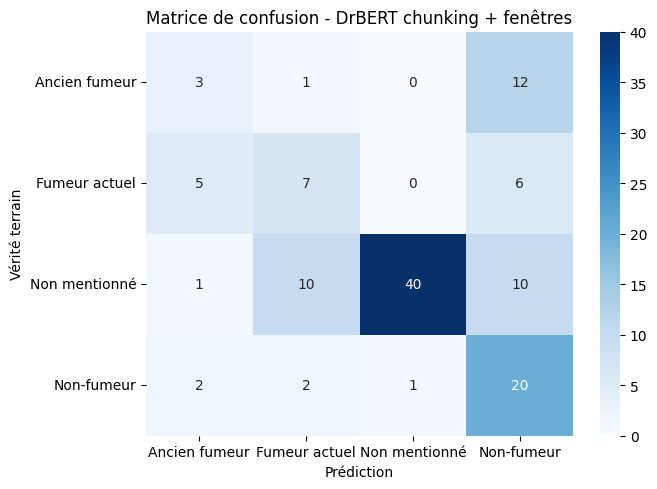

Inférence : 0.7 s | VRAM : 1.83 Go


In [11]:
if DEVICE == "cuda":
    torch.cuda.reset_peak_memory_stats()
t0 = time.perf_counter()
test_probs_seq = predict_probs(model, tokenizer, test_records, batch_size=EVAL_BS)
test_seq_doc = [r["doc_id"] for r in test_records]
test_agg = aggregate_probs(test_seq_doc, test_probs_seq, method=AGG_METHOD, tau=AGG_TAU)
infer_time_s = time.perf_counter() - t0
peak_vram_infer = vram_peak_gb()

test_agg = test_agg.loc[df_test["id"]]
y_true = df_test["label_id"].values
y_pred = test_agg.values.argmax(1)

# score avec l'autre méthode d'agrégation, pour comparer
alt_method = "mean" if AGG_METHOD == "max_evidence" else "max_evidence"
alt = aggregate_probs(test_seq_doc, test_probs_seq, method=alt_method, tau=AGG_TAU).loc[df_test["id"]]
f1_alt = f1_score(y_true, alt.values.argmax(1), average="macro")
print(f"F1 macro avec '{alt_method}' : {f1_alt:.4f}\n")

info_test = test_info.set_index("doc_id").loc[df_test["id"]]
timings = {"train_time_s": round(train_time_s, 1), "inference_time_s": round(infer_time_s, 2),
           "inference_ms_per_doc": round(1000 * infer_time_s / len(df_test), 1),
           "preprocessing_test_s": round(prep_test_s, 2),
           "peak_vram_train_gb": peak_vram_train, "peak_vram_infer_gb": peak_vram_infer}
metrics, pred_df = evaluate_and_save(
    "DrBERT chunking + fenêtres", df_test["id"].values, y_true, y_pred, test_agg.values, timings,
    extra_cols={"seq_type": info_test["seq_type"].values, "n_doc_tokens": info_test["n_doc_tokens"].values,
                "n_seqs": info_test["n_seqs"].values},
    extra_metrics={"aggregation": AGG_METHOD, "aggregation_tau": AGG_TAU, "f1_macro_alt_aggregation": round(f1_alt, 4),
                   "best_val_f1_macro": round(float(trainer.state.best_metric), 4),
                   "n_test_sequences": len(test_records)},
    config={"model": MODEL_CHECKPOINT, "max_len": MAX_LEN, "ctx_tokens": CTX_TOKENS, "epochs": EPOCHS, "lr": LR,
            "train_bs": TRAIN_BS, "grad_acc": GRAD_ACC, "class_weights": USE_CLASS_WEIGHTS},
)
print(f"Inférence : {infer_time_s:.1f} s | VRAM : {peak_vram_infer} Go")

## 5.7 Biais de longueur

On vérifie que le modèle ne s'appuie pas sur la longueur des documents plutôt que sur leur contenu :
- performances par quartile de longueur et par type de séquence ;
- longueur des documents selon la classe dans le train ;
- ratio de padding pour les documents gardés en entier ;
- inférence avec un padding fixe à 512 : grâce à l'`attention_mask`, les prédictions ne devraient pas changer.

,n_docs,accuracy,f1_macro,% Non mentionné
len_bin,,,,
"(77.999, 327.0]",30.0,0.600,0.191,0.967
"(327.0, 532.5]",30.0,0.500,0.329,0.633
"(532.5, 805.5]",30.0,0.700,0.632,0.333
"(805.5, 3689.0]",30.0,0.533,0.589,0.100


,n_docs,accuracy,f1_macro,% Non mentionné
seq_type,,,,
chunk,14.0,0.929,0.241,1.000
full,53.0,0.528,0.260,0.849
window,53.0,0.547,0.611,0.038


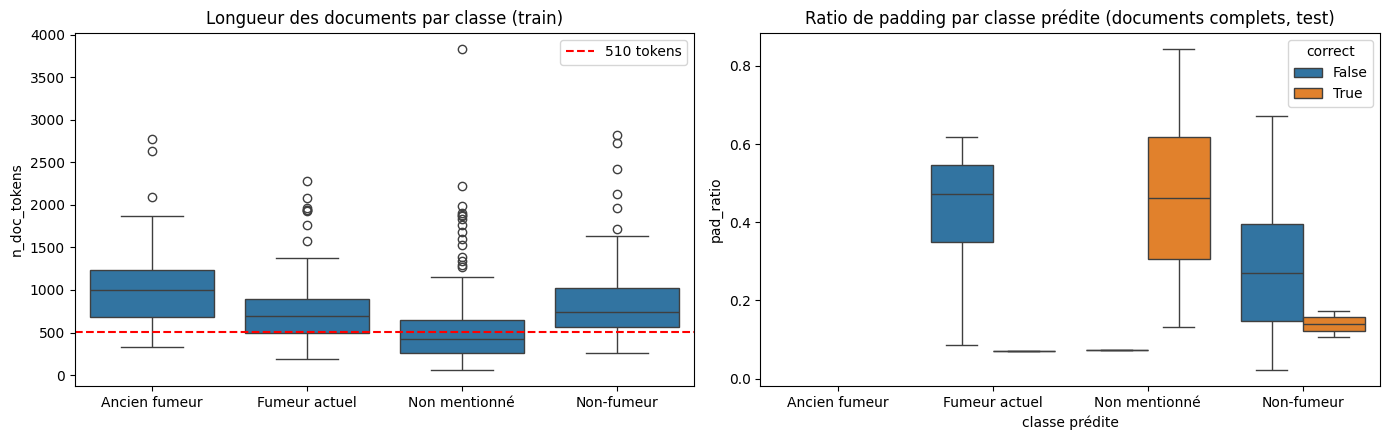

,count,mean,median
correct,,,
False,25,0.345,0.355
True,28,0.420,0.420


Prédictions identiques : 100.0% | écart max de probabilité : 0.0003


In [12]:
an = pred_df.copy()
an["correct"] = an["y_true_id"] == an["y_pred_id"]
an["len_bin"] = pd.qcut(an["n_doc_tokens"], q=4, duplicates="drop")


def group_perf(g):
    return pd.Series({"n_docs": len(g), "accuracy": g["correct"].mean(),
                      "f1_macro": f1_score(g["y_true_id"], g["y_pred_id"], average="macro", labels=range(NUM_LABELS), zero_division=0),
                      "% Non mentionné": (g["y_true"] == "Non mentionné").mean()})


cols = ["correct", "y_true_id", "y_pred_id", "y_true"]
display(an.groupby("len_bin", observed=True)[cols].apply(group_perf).round(3))
display(an.groupby("seq_type")[cols].apply(group_perf).round(3))

tr = train_info.assign(label=lambda d: d["label_id"].map(ID2LABEL))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=tr, x="label", y="n_doc_tokens", order=CLASSES, ax=axes[0])
axes[0].axhline(BODY_LEN, color="red", ls="--", label=f"{BODY_LEN} tokens")
axes[0].legend()
axes[0].set_title("Longueur des documents par classe (train)")
axes[0].set_xlabel("")

full = an[an["seq_type"] == "full"].copy()
full["pad_ratio"] = 1 - (full["n_doc_tokens"] + 2) / MAX_LEN
sns.boxplot(data=full, x="y_pred", y="pad_ratio", hue="correct", order=CLASSES, ax=axes[1])
axes[1].set_title("Ratio de padding par classe prédite (documents complets, test)")
axes[1].set_xlabel("classe prédite")
plt.tight_layout()
plt.show()

display(full.groupby("correct")["pad_ratio"].agg(["count", "mean", "median"]).round(3))

# même inférence avec un padding fixe à 512
probs_fixed = predict_probs(model, tokenizer, test_records, batch_size=EVAL_BS, pad_to=MAX_LEN)
agg_fixed = aggregate_probs(test_seq_doc, probs_fixed, method=AGG_METHOD, tau=AGG_TAU).loc[df_test["id"]]
same_pred = (agg_fixed.values.argmax(1) == y_pred).mean()
max_diff = np.abs(agg_fixed.values - test_agg.values).max()
print(f"Prédictions identiques : {same_pred:.1%} | écart max de probabilité : {max_diff:.4f}")

Le padding est masqué par l'attention, le dernier test doit donc donner les mêmes prédictions. Ce qui compte plus, c'est le lien entre longueur et classe : les longs documents sans mention sont presque tous « Non mentionné », donc bien les classer n'est pas forcément un raccourci du modèle. Les cas intéressants sont les documents découpés en chunks dont la vraie classe est une classe tabac (mentions ratées par la regex).

In [13]:
import shutil
shutil.rmtree(CKPT_DIR, ignore_errors=True)
free_memory()